# Basic Vector Data Analysis with GRASS

Rajveer Bishnoi  
2026-07-05

# Introduction

Vector data represents geographic features as **points**, **lines**, and
**areas**, each linked to a table of **attributes**. GRASS has a large
family of `v.*` tools for working with them. This tutorial introduces
the operations you will reach for most often, using a single worked
example: analyzing how schools in central Raleigh, North Carolina relate
to major roads and ZIP code areas.

Along the way we will:

- explore a vector map and its attribute table,
- **clip** a map to the study area with
  [v.clip](https://grass.osgeo.org/grass-stable/manuals/v.clip.html),
- **select by attribute** with
  [v.extract](https://grass.osgeo.org/grass-stable/manuals/v.extract.html),
- **buffer** features with
  [v.buffer](https://grass.osgeo.org/grass-stable/manuals/v.buffer.html),
- **select by location** with
  [v.select](https://grass.osgeo.org/grass-stable/manuals/v.select.html),
- perform spatial operations with
  [v.overlay](https://grass.osgeo.org/grass-stable/manuals/v.overlay.html),
  and
- count features per area with
  [v.vect.stats](https://grass.osgeo.org/grass-stable/manuals/v.vect.stats.html).

> **Demo dataset**
>
> This tutorial uses the GRASS [North Carolina sample
> dataset](https://grass.osgeo.org/sampledata/raleigh_northcarolina_usa_epsg6542.zip)
> (`raleigh_northcarolina_usa_epsg6542`), which includes `schools`
> (points), `roads` (lines), and `zipcodes` (areas). The data lives in
> the `PERMANENT` mapset, and we work in the empty `mapset_1` that comes
> with it.

> **How to run this tutorial**
>
> The code uses the GRASS Python API in a Jupyter notebook. If you are
> new to running GRASS from Python, see the [Get started with GRASS &
> Python](https://grass-tutorials.osgeo.org/content/tutorials/get_started/fast_track_grass_and_python.html)
> tutorial. Every step also works from the GRASS GUI or command line;
> just use the tool name (for example `v.buffer`) with the same
> parameters.

# Setup and exploration

Start a GRASS session in `mapset_1` and set the [computational
region](https://grass.osgeo.org/grass-stable/manuals/g.region.html) to
the dataset’s default, a 24 x 13.5 km window over central Raleigh. For
vector-only work the region mainly controls what the maps display, but
we will also use it to clip a layer below.

In [1]:
import sys
import subprocess

sys.path.append(
    subprocess.check_output(["grass", "--config", "python_path"], text=True).strip()
)

import grass.script as gs
import grass.jupyter as gj
from grass.tools import Tools

session = gj.init("~/grassdata/raleigh_northcarolina_usa_epsg6542/mapset_1")
tools = Tools()

tools.g_region(flags="d")

> **GRASS version**
>
> The examples use the [grass.tools
> API](https://grass.osgeo.org/grass-stable/manuals/python_intro.html)
> (the `Tools` class), introduced in GRASS 8.5. On earlier versions you
> can run the same tools with `gs.run_command("v.buffer", ...)`.

Before analyzing a layer, it helps to know what it contains.
[v.info](https://grass.osgeo.org/grass-stable/manuals/v.info.html)
reports the feature types and counts, and its `-c` flag lists the
attribute columns.

In [2]:
# Feature summary (points, lines, areas ...)
print(tools.v_info(map="schools", flags="t").text)

# Attribute columns
print(tools.v_info(map="schools", flags="c").text)

`schools` has 61 point features. Let’s look at the attribute table
itself.
[v.db.select](https://grass.osgeo.org/grass-stable/manuals/v.db.select.html)
can return the table as JSON, which [pandas](https://pandas.pydata.org/)
turns into a tidy table:

In [3]:
import pandas as pd

pd.DataFrame(
    tools.v_db_select(
        map="schools",
        columns="school_nam,phys_city,num_teach,elem,middle,high",
        format="json",
    )["records"]
).head()

| school_nam           | phys_city | num_teach | elem | middle | high |
|----------------------|-----------|-----------|------|--------|------|
| Adams Elementary     | Cary      | 54        | yes  |        |      |
| Exploris             | Raleigh   | 17        |      | yes    |      |
| Athens Drive High    | Raleigh   | 128       |      |        | yes  |
| Aversboro Elementary | Garner    | 39        | yes  |        |      |
| Longview             | Raleigh   | 27        |      | yes    | yes  |

The `elem`, `middle`, and `high` columns are set to `yes` for each level
a school teaches. A school can teach more than one: Longview covers
grades 6 to 12, so it has both `middle` and `high` set. We use these
columns next to select schools by attribute.

The study area is a rectangle over central Raleigh, and the schools and
roads stop at its edge. The ZIP code areas do not: they are whole, and
13 of the 15 reach beyond it. Counting schools per whole ZIP code would
undercount the ones that only partly overlap the study area, because
their schools outside it are not in the data.
[v.clip](https://grass.osgeo.org/grass-stable/manuals/v.clip.html) with
the `-r` flag clips the ZIP code areas to the computational region, so
we only work with the part we have data for:

In [4]:
tools.v_clip(input="zipcodes", output="zipcodes_raleigh", flags="r")

Let’s draw an overview map: the clipped ZIP code areas, the roads, and
the schools. In
[grass.jupyter](https://grass.osgeo.org/grass-stable/manuals/libpython/grass.jupyter.html),
a `Map` object collects display layers and renders them together.

In [5]:
overview = gj.Map(width=500)
overview.d_vect(map="zipcodes_raleigh", type="area",
                fill_color="235:235:235", color="180:180:180")
overview.d_vect(map="roads", color="190:190:190", width=1)
overview.d_vect(map="schools", icon="basic/circle", size=7,
                fill_color="200:30:30", color="white")
overview.d_barscale(flags="n", at=(1, 10), length=5, units="kilometers",
                    bgcolor="white")
overview.show()

<figure>
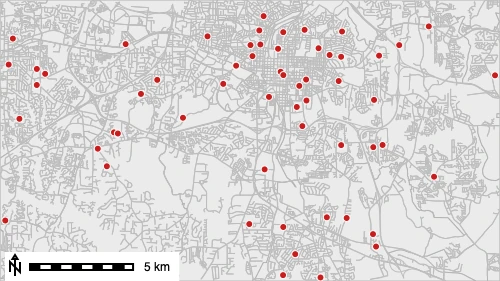
<figcaption aria-hidden="true">Central Raleigh: ZIP code areas (gray),
all roads, and the 61 schools (red).</figcaption>
</figure>

# Selecting by attribute

To keep just the **elementary schools** (`elem = 'yes'`), use
[v.extract](https://grass.osgeo.org/grass-stable/manuals/v.extract.html)
with a SQL `where` clause.

In [6]:
tools.v_extract(input="schools", output="elementary", where="elem = 'yes'")
print(tools.v_info(map="elementary", flags="t").text)  # points=31

The same tool picks out the major roads. The roads come from
OpenStreetMap, where the `highway` column classifies each segment;
motorways, trunk roads, and primary roads make up the major road
network.

In [7]:
tools.v_extract(input="roads", output="roadsmajor",
                where="highway IN ('motorway', 'trunk', 'primary')")

In [8]:
attr_map = gj.Map(width=500)
attr_map.d_vect(map="zipcodes_raleigh", type="area",
                fill_color="235:235:235", color="180:180:180")
attr_map.d_vect(map="roadsmajor", color="90:90:90", width=1)
attr_map.d_vect(map="schools", icon="basic/circle", size=6,
                fill_color="180:180:180", color="none")
attr_map.d_vect(map="elementary", icon="basic/circle", size=8,
                fill_color="30:120:200", color="white")
attr_map.d_barscale(flags="n", at=(1, 10), length=5, units="kilometers",
                    bgcolor="white")
attr_map.show()

<figure>
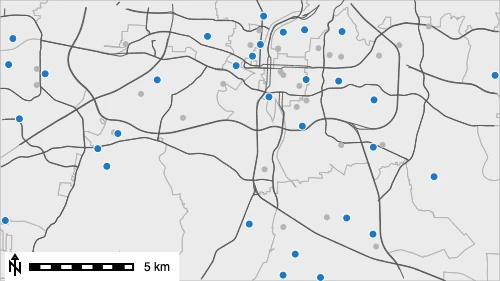
<figcaption aria-hidden="true">Elementary schools (blue) selected from
all schools (gray) by attribute.</figcaption>
</figure>

# Buffering

A **buffer** is an area of a given radius around features. Here we
buffer the major roads by 500 m with
[v.buffer](https://grass.osgeo.org/grass-stable/manuals/v.buffer.html)
to represent an “along a major road” corridor. The result is an area
map.

In [9]:
tools.v_buffer(input="roadsmajor", output="road_buffer", distance=500)

In [10]:
buffer_map = gj.Map(width=500)
buffer_map.d_vect(map="zipcodes_raleigh", type="area",
                  fill_color="235:235:235", color="180:180:180")
buffer_map.d_vect(map="road_buffer", type="area", fill_color="255:200:120", color="none")
buffer_map.d_vect(map="roadsmajor", color="120:70:20", width=1)
buffer_map.d_barscale(flags="n", at=(1, 10), length=5, units="kilometers",
                      bgcolor="white")
buffer_map.show()

<figure>
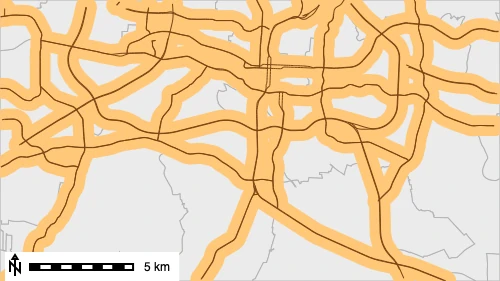
<figcaption aria-hidden="true">A 500 m buffer (orange) around the major
roads.</figcaption>
</figure>

# Selecting by location

Now we combine two layers spatially:
[v.select](https://grass.osgeo.org/grass-stable/manuals/v.select.html)
keeps features of one map based on their spatial relationship to
another. With `operator=overlap`, we keep the elementary schools that
fall inside the road buffer.

In [11]:
tools.v_select(ainput="elementary", binput="road_buffer",
               output="schools_near", operator="overlap")
print(tools.v_info(map="schools_near", flags="t").text)  # points=16

**16 out of the 31 elementary schools** lie within 500 m of a major
road. Only 4 of them are that close to a motorway or trunk road; the
other 12 qualify because of a primary road.

In [12]:
near_map = gj.Map(width=500)
near_map.d_vect(map="zipcodes_raleigh", type="area",
                fill_color="235:235:235", color="180:180:180")
near_map.d_vect(map="road_buffer", type="area", fill_color="255:230:200", color="none")
near_map.d_vect(map="roadsmajor", color="150:110:60", width=1)
near_map.d_vect(map="elementary", icon="basic/circle", size=7,
                fill_color="150:150:150", color="none")
near_map.d_vect(map="schools_near", icon="basic/circle", size=9,
                fill_color="20:150:60", color="white")
near_map.d_barscale(flags="n", at=(1, 10), length=5, units="kilometers",
                    bgcolor="white")
near_map.show()

<figure>
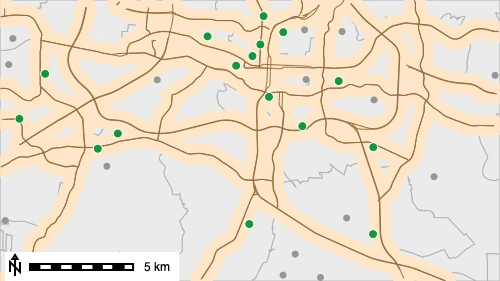
<figcaption aria-hidden="true">Elementary schools within 500 m of a
major road (green) versus the rest (gray).</figcaption>
</figure>

# Overlaying layers

[v.overlay](https://grass.osgeo.org/grass-stable/manuals/v.overlay.html)
combines two area maps with set operations. With `operator=and` we get
the **intersection**, the part of the road corridor that falls within
each ZIP code area. The output keeps the attributes of both inputs
(prefixed `a_` and `b_`).

In [13]:
tools.v_overlay(ainput="road_buffer", binput="zipcodes_raleigh",
                operator="and", output="buffer_by_zip")

In [14]:
overlay_map = gj.Map(width=500)
overlay_map.d_vect(map="zipcodes_raleigh", type="area",
                   fill_color="235:235:235", color="180:180:180")
overlay_map.d_vect(map="buffer_by_zip", type="area",
                   fill_color="120:180:220", color="80:80:80", width=1)
overlay_map.d_barscale(flags="n", at=(1, 10), length=5, units="kilometers",
                       bgcolor="white")
overlay_map.show()

<figure>
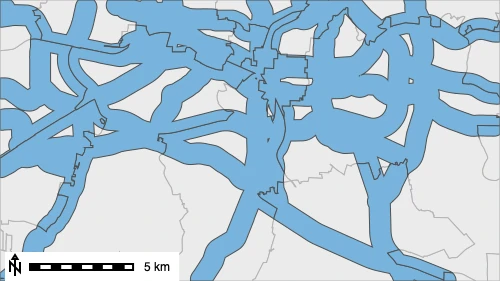
<figcaption aria-hidden="true">The road buffer intersected with the ZIP
code areas; polygons are split at ZIP boundaries.</figcaption>
</figure>

Because each piece now carries its ZIP code, we can measure how much of
each ZIP code is within reach of a major road.
[v.to.db](https://grass.osgeo.org/grass-stable/manuals/v.to.db.html)
computes the area of every polygon, and a grouped SQL query with
[db.select](https://grass.osgeo.org/grass-stable/manuals/db.select.html)
sums it per ZIP code:

In [15]:
tools.v_to_db(map="buffer_by_zip", option="area", columns="reach_area", units="kilometers")

# db.select also returns JSON, so the same pandas pattern works here
pd.DataFrame(
    tools.db_select(
        sql="SELECT b_ZCTA5CE10 AS zip_code, "
            "ROUND(SUM(reach_area), 1) AS reach_km2 "
            "FROM buffer_by_zip GROUP BY b_ZCTA5CE10 ORDER BY reach_km2 DESC",
        format="json",
    )["records"]
).head(6)

| zip_code | reach_km2 |
|----------|-----------|
| 27610    | 42.6      |
| 27606    | 27.7      |
| 27603    | 22.7      |
| 27607    | 14.4      |
| 27529    | 14.1      |
| 27511    | 10.9      |

ZIP code 27610 leads because it has both the most area inside the study
area and the most kilometers of major road.

# Counting features per area

A common summary is “how many points fall in each area?”
[v.vect.stats](https://grass.osgeo.org/grass-stable/manuals/v.vect.stats.html)
counts the points of one map within the areas of another and writes the
result to the area map’s attribute table. We first create a copy of the
ZIP codes map with
[g.copy](https://grass.osgeo.org/grass-stable/manuals/g.copy.html) so
the original is untouched.

In [16]:
tools.g_copy(vector=("zipcodes_raleigh", "zip_counts"))
tools.v_vect_stats(points="schools", areas="zip_counts", count_column="n_schools")

Each ZIP code now has an `n_schools` value (ranging from 0 to 16 here).
We map it as a choropleth with
[d.vect.thematic](https://grass.osgeo.org/grass-stable/manuals/d.vect.thematic.html),
using quantile classes so each color holds a similar number of areas.

In [17]:
choropleth = gj.Map(width=500)
choropleth.d_vect_thematic(
    map="zip_counts", column="n_schools", algorithm="qua", nclasses=5,
    colors="255:245:215,255:200:120,240:140:60,200:70:30,140:20:20",
)
choropleth.d_vect(map="roadsmajor", color="120:120:120", width=1)
choropleth.d_barscale(flags="n", at=(1, 10), length=5, units="kilometers",
                      bgcolor="white")
choropleth.show()

<figure>
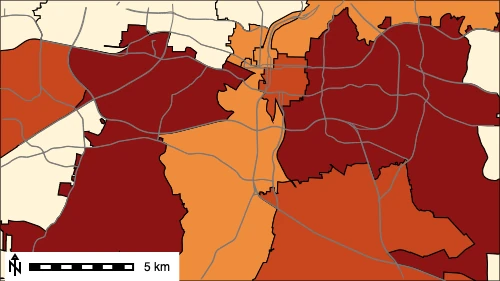
<figcaption aria-hidden="true">Schools per ZIP code area, classified
into five quantiles from light (few) to dark (many).</figcaption>
</figure>

See also a dedicated tutorial on [Making Thematic
Maps](../thematic_maps/thematic_maps.qmd).

# Summary

Using the schools, roads, and ZIP codes of central Raleigh, we have
worked through the core vector toolkit in GRASS:

- exploring features and attributes with `v.info` and `v.db.select`,
- **clipping** a map to the study area (`v.clip`),
- **selecting by attribute** (`v.extract`) and **by location**
  (`v.select`),
- **buffering** (`v.buffer`) and **overlaying** (`v.overlay`) layers,
  and
- **counting** points per area (`v.vect.stats`) for a thematic map.